# Autoregressive Image Modeling



## Configurations and initializations

This section loads libraries and configurations for various tasks for this course

In [1]:
## Standard libraries
import os
import math
import numpy as np
import pandas as pd

## Imports for plotting
import matplotlib.pyplot as plt
plt.set_cmap('cividis')
%matplotlib inline
from IPython.display import set_matplotlib_formats
%config InlineBackend.figure_formats = ['svg', 'pdf']
from matplotlib.colors import to_rgb
import seaborn as sns

## Progress bar
from tqdm.notebook import tqdm

## PyTorch
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.utils.data as data
import torch.optim as optim

# Torchvision
import torchvision
from torchvision.datasets import MNIST
from torchvision import transforms

# Path to the folder where the datasets are/should be downloaded (e.g. MNIST)
DATASET_PATH = "../data"

# Path to the folder where the models are saved
CHECKPOINT_PATH = "./"

# Ensure that all operations are deterministic on GPU (if used) for reproducibility
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

# Fetching the device that will be used throughout this notebook
device = torch.device("cpu") if not torch.cuda.is_available() else torch.device("cuda:0")
print("Using device", device)

Using device cuda:0


<Figure size 640x480 with 0 Axes>

In [2]:
# Convert images from 0-1 to 0-255 (integers).
def discretize(sample):
    return (sample * 255).to(torch.long)

# Transformations applied on each image => only make them a tensor
transform = transforms.Compose([transforms.ToTensor(), discretize])

# Loading the training dataset. We need to split it into a training and validation part
train_dataset = MNIST(root=DATASET_PATH, train=True, transform=transform, download=True)

#pl.seed_everything(42)
train_set, val_set = torch.utils.data.random_split(train_dataset, [50000, 10000])

# Loading the test set
test_set = MNIST(root=DATASET_PATH, train=False, transform=transform, download=True)

# We define a set of data loaders that we can use for various purposes later.
train_loader = data.DataLoader(train_set, batch_size=128, shuffle=True, drop_last=True, pin_memory=True, num_workers=0)
val_loader = data.DataLoader(val_set, batch_size=128, shuffle=False, drop_last=False, num_workers=0)
test_loader = data.DataLoader(test_set, batch_size=128, shuffle=False, drop_last=False, num_workers=0)

print('Train size:', len(train_loader.dataset))
print('Validation size:', len(val_loader.dataset))
print('Test size:', len(test_loader.dataset))

100%|██████████| 9.91M/9.91M [00:02<00:00, 4.57MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 134kB/s]
100%|██████████| 1.65M/1.65M [00:01<00:00, 1.28MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 7.57MB/s]

Train size: 50000
Validation size: 10000
Test size: 10000


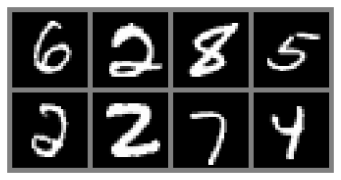

In [3]:
def show_imgs(imgs):
    num_imgs = imgs.shape[0] if isinstance(imgs, torch.Tensor) else len(imgs)
    nrow = min(num_imgs, 4)
    ncol = int(math.ceil(num_imgs/nrow))
    imgs = torchvision.utils.make_grid(imgs, nrow=nrow, pad_value=128)
    imgs = imgs.clamp(min=0, max=255)
    np_imgs = imgs.cpu().numpy()
    plt.figure(figsize=(1.5*nrow, 1.5*ncol))
    plt.imshow(np.transpose(np_imgs, (1,2,0)), interpolation='nearest')
    plt.axis('off')
    plt.show()

show_imgs([train_set[i][0] for i in range(8)])

## Define Masked Cnvolutions

In [4]:
class MaskedConvolution(nn.Module):

    def __init__(self, c_in, c_out, mask, **kwargs):
        """
        Implements a convolution with mask applied on its weights.
        Inputs:
            c_in - Number of input channels
            c_out - Number of output channels
            mask - Tensor of shape [kernel_size_H, kernel_size_W] with 0s where
                   the convolution should be masked, and 1s otherwise.
            kwargs - Additional arguments for the convolution
        """
        super().__init__()
        # For simplicity: calculate padding automatically
        kernel_size = (mask.shape[0], mask.shape[1])

        # Actual convolution
        self.conv = nn.Conv2d(c_in, c_out, kernel_size, padding='same', **kwargs)

        # Mask as buffer => it is no parameter but still a tensor of the module
        # (must be moved with the devices)
        self.register_buffer('mask', mask[None,None].to(device))

    def forward(self, x):
        self.conv.weight.data *= self.mask # Ensures zero's at masked positions
        return self.conv(x)

In [5]:
class VerticalStackConvolution(MaskedConvolution):

    def __init__(self, c_in, c_out, kernel_size=3, mask_center=False, **kwargs):
        # Mask out all pixels below. For efficiency, we could also reduce the kernel
        # size in height, but for simplicity, we stick with masking here.
        mask = torch.ones(kernel_size, kernel_size)
        mask[kernel_size//2+1:,:] = 0

        # For the very first convolution, we will also mask the center row
        if mask_center:
            mask[kernel_size//2,:] = 0

        super().__init__(c_in, c_out, mask, **kwargs)

class HorizontalStackConvolution(MaskedConvolution):

    def __init__(self, c_in, c_out, kernel_size=3, mask_center=False, **kwargs):
        # Mask out all pixels on the left. Note that our kernel has a size of 1
        # in height because we only look at the pixel in the same row.
        mask = torch.ones(1,kernel_size)
        mask[0,kernel_size//2+1:] = 0

        # For the very first convolution, we will also mask the center pixel
        if mask_center:
            mask[0,kernel_size//2] = 0

        super().__init__(c_in, c_out, mask, **kwargs)

## PixelCNN without Gating and dilations

Instead of the GatedMaskConv from the tutorial, we defined a MaskedConvLayer for the model.

In [7]:
class MaskedConvLayer(nn.Module):
    def __init__(self, c_in, kernel_size=9, **kwargs):
        super().__init__()

        self.vert = nn.Sequential(
            VerticalStackConvolution(c_in, c_in, kernel_size=kernel_size, **kwargs),
            nn.ELU()
        )

        self.horiz_conv = HorizontalStackConvolution(c_in, c_in, kernel_size=kernel_size, **kwargs)
        self.vert_to_horiz = nn.Conv2d(c_in, c_in, kernel_size=1)
        self.horiz_activation = nn.ELU()

    def forward(self, v_stack, h_stack):
        v_out = self.vert(v_stack)  # (conv + ELU)
        h_conv = self.horiz_conv(h_stack)
        h_out = h_conv + self.vert_to_horiz(v_out)  # Inject vertical into horizontal
        h_out = self.horiz_activation(h_out)

        return v_stack + v_out, h_stack + h_out  # Residual addition


Before you start training, you have to choose parameters for your model; How to choose the "most suitable"?

We can check the full receptive field of the model on an MNIST image of size $28\times 28$:

In [8]:
class PixelCNN(nn.Module):

    def __init__(self, c_in, c_hidden = 64, kernel_size=9, n_layers=7):
        super().__init__()

        self.conv_vstack = VerticalStackConvolution(c_in, c_hidden, kernel_size=kernel_size, mask_center=True)
        self.conv_hstack = HorizontalStackConvolution(c_in, c_hidden, kernel_size=kernel_size, mask_center=True)

        self.conv_layers = nn.ModuleList([
            MaskedConvLayer(c_hidden, kernel_size=kernel_size)
            for _ in range(n_layers)
        ])

        self.conv_out = nn.Conv2d(c_hidden, c_in * 256, kernel_size=1)


    def forward(self, x):
        """
        Forward image through model and return logits for each pixel.
        Inputs:
            x - Image tensor with integer values between 0 and 255.
        """
        # Scale input from 0 to 255 back to -1 to 1
        x = (x.float() / 255.0) * 2 - 1

        # Initial convolutions
        v_stack = self.conv_vstack(x)
        h_stack = self.conv_hstack(x)

        # Other Convolutions
        for layer in self.conv_layers:
            v_stack, h_stack = layer(v_stack, h_stack)

        # Apply ELU before 1x1 convolution for non-linearity on residual connection
        out = self.conv_out(F.elu(h_stack + v_stack))

        # Output dimensions: [Batch, Classes, Channels, Height, Width]
        out = out.reshape(out.shape[0], 256, out.shape[1]//256, out.shape[2], out.shape[3])

        return out

    def calc_nll(self, x):
        # Forward pass with bpd (bits per dimension) negative log likelihood calculation
        logits = self.forward(x)  # [B, 256, 1, H, W]
        logits = logits.squeeze(2)  # Remove channel dimension -> [B, 256, H, W]
        targets = x.squeeze(1)      # [B, H, W], integer labels (0-255)

        return F.cross_entropy(logits, targets, reduction='mean')

    @torch.no_grad()
    def sample(self, img_shape, img=None):
        """
        Sampling function for the autoregressive model.
        Inputs:
            img_shape - Shape of the image to generate (B,C,H,W)
            img (optional) - If given, this tensor will be used as
                             a starting image. The pixels to fill
                             should be -1 in the input tensor.
        """
        # Create empty image
        if img is None:
            img = torch.zeros(img_shape, dtype=torch.long).to(device) - 1
        # Generation loop
        for h in tqdm(range(img_shape[2]), leave=False):
            for w in range(img_shape[3]):
                for c in range(img_shape[1]):
                    # Skip if not to be filled (-1)
                    if (img[:,c,h,w] != -1).all().item():
                        continue
                    # For efficiency, we only have to input the upper part of the image
                    # as all other parts will be skipped by the masked convolutions anyways
                    pred = self.forward(img[:,:,:h+1,:])
                    probs = F.softmax(pred[:,:,c,h,w], dim=-1)
                    img[:,c,h,w] = torch.multinomial(probs, num_samples=1).squeeze(dim=-1)
        return img

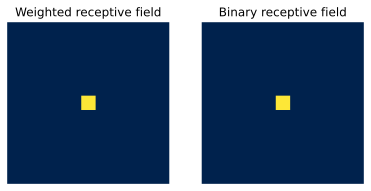

In [9]:
inp_img = torch.zeros(1, 1, 11, 11)
inp_img.requires_grad_()

def show_center_recep_field(img, out):
    """
    Calculates the gradients of the input with respect to the output center pixel,
    and visualizes the overall receptive field.
    Inputs:
        img - Input image for which we want to calculate the receptive field on.
        out - Output features/loss which is used for backpropagation, and should be
              the output of the network/computation graph.
    """
    # Determine gradients
    loss = out[0,:,img.shape[2]//2,img.shape[3]//2].sum() # L1 loss for simplicity
    loss.backward(retain_graph=True) # Retain graph as we want to stack multiple layers and show the receptive field of all of them
    img_grads = img.grad.abs()
    img.grad.fill_(0) # Reset grads

    # Plot receptive field
    img = img_grads.squeeze().cpu().numpy()
    fig, ax = plt.subplots(1,2)
    pos = ax[0].imshow(img)
    ax[1].imshow(img>0)
    # Mark the center pixel in red if it doesn't have any gradients (should be the case for standard autoregressive models)
    show_center = (img[img.shape[0]//2,img.shape[1]//2] == 0)
    if show_center:
        center_pixel = np.zeros(img.shape + (4,))
        center_pixel[center_pixel.shape[0]//2,center_pixel.shape[1]//2,:] = np.array([1.0, 0.0, 0.0, 1.0])
    for i in range(2):
        ax[i].axis('off')
        if show_center:
            ax[i].imshow(center_pixel)
    ax[0].set_title("Weighted receptive field")
    ax[1].set_title("Binary receptive field")
    plt.show()
    plt.close()

show_center_recep_field(inp_img, inp_img)

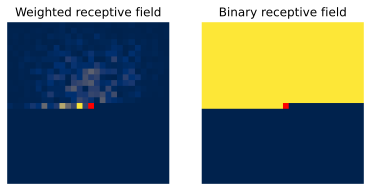

In [10]:
test_model = PixelCNN(c_in=1, c_hidden=64).to('cpu')      # adjust according to your model
inp = torch.zeros(1,1,28,28).to('cpu')                    # do not remove the 'cpu' here
inp.requires_grad_()
out = test_model(inp)
show_center_recep_field(inp, out.squeeze(dim=2))
del inp, out, test_model

## Model Training

In [11]:
model = PixelCNN(c_in=1, c_hidden=64, kernel_size=7, n_layers=7)       # adjust according to your model
print("Num params: {:,}".format(sum(p.numel() for p in model.parameters())))

model = torch.compile(model.to(device))

optimizer = optim.Adam(model.parameters(), lr=1e-3)
scheduler = optim.lr_scheduler.StepLR(optimizer, 1, gamma=0.99)
epochs = 15

Num params: 1,656,000


  0%|          | 0/390 [00:00<?, ?it/s]

  0%|          | 0/79 [00:00<?, ?it/s]

Epoch 1/15, Train Loss: 0.9551, Val Loss: 0.8372


  0%|          | 0/28 [00:00<?, ?it/s]

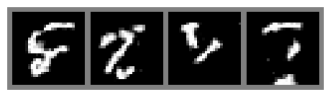

  0%|          | 0/390 [00:00<?, ?it/s]

  0%|          | 0/79 [00:00<?, ?it/s]

Epoch 2/15, Train Loss: 0.8254, Val Loss: 0.8125


  0%|          | 0/28 [00:00<?, ?it/s]

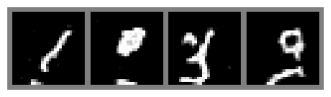

  0%|          | 0/390 [00:00<?, ?it/s]

  0%|          | 0/79 [00:00<?, ?it/s]

Epoch 3/15, Train Loss: 0.8014, Val Loss: 0.7917


  0%|          | 0/28 [00:00<?, ?it/s]

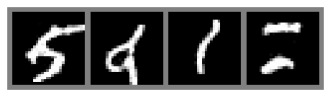

  0%|          | 0/390 [00:00<?, ?it/s]

  0%|          | 0/79 [00:00<?, ?it/s]

Epoch 4/15, Train Loss: 0.7842, Val Loss: 0.7778


  0%|          | 0/28 [00:00<?, ?it/s]

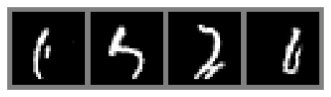

  0%|          | 0/390 [00:00<?, ?it/s]

  0%|          | 0/79 [00:00<?, ?it/s]

Epoch 5/15, Train Loss: 0.7752, Val Loss: 0.7702


  0%|          | 0/28 [00:00<?, ?it/s]

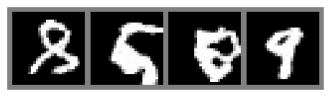

  0%|          | 0/390 [00:00<?, ?it/s]

  0%|          | 0/79 [00:00<?, ?it/s]

Epoch 6/15, Train Loss: 0.7670, Val Loss: 0.7642


  0%|          | 0/28 [00:00<?, ?it/s]

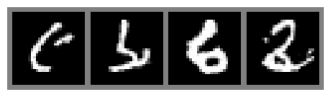

  0%|          | 0/390 [00:00<?, ?it/s]

  0%|          | 0/79 [00:00<?, ?it/s]

Epoch 7/15, Train Loss: 0.7666, Val Loss: 0.7618


  0%|          | 0/28 [00:00<?, ?it/s]

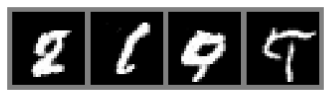

  0%|          | 0/390 [00:00<?, ?it/s]

  0%|          | 0/79 [00:00<?, ?it/s]

Epoch 8/15, Train Loss: 0.7576, Val Loss: 0.7536


  0%|          | 0/28 [00:00<?, ?it/s]

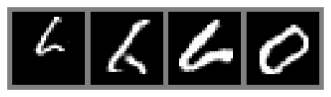

  0%|          | 0/390 [00:00<?, ?it/s]

  0%|          | 0/79 [00:00<?, ?it/s]

Epoch 9/15, Train Loss: 0.7535, Val Loss: 0.7474


  0%|          | 0/28 [00:00<?, ?it/s]

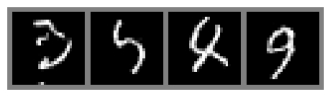

  0%|          | 0/390 [00:00<?, ?it/s]

  0%|          | 0/79 [00:00<?, ?it/s]

Epoch 10/15, Train Loss: 0.7471, Val Loss: 0.7491


  0%|          | 0/28 [00:00<?, ?it/s]

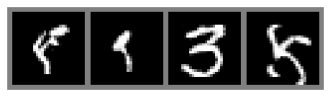

  0%|          | 0/390 [00:00<?, ?it/s]

  0%|          | 0/79 [00:00<?, ?it/s]

Epoch 11/15, Train Loss: 0.7424, Val Loss: 0.7740


  0%|          | 0/28 [00:00<?, ?it/s]

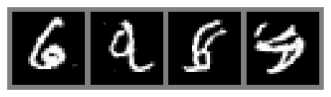

  0%|          | 0/390 [00:00<?, ?it/s]

  0%|          | 0/79 [00:00<?, ?it/s]

Epoch 12/15, Train Loss: 0.7374, Val Loss: 0.7301


  0%|          | 0/28 [00:00<?, ?it/s]

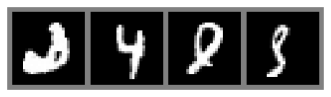

  0%|          | 0/390 [00:00<?, ?it/s]

  0%|          | 0/79 [00:00<?, ?it/s]

Epoch 13/15, Train Loss: 0.7286, Val Loss: 0.7226


  0%|          | 0/28 [00:00<?, ?it/s]

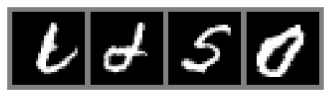

  0%|          | 0/390 [00:00<?, ?it/s]

  0%|          | 0/79 [00:00<?, ?it/s]

Epoch 14/15, Train Loss: 0.7303, Val Loss: 0.7208


  0%|          | 0/28 [00:00<?, ?it/s]

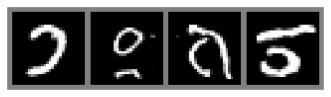

  0%|          | 0/390 [00:00<?, ?it/s]

  0%|          | 0/79 [00:00<?, ?it/s]

Epoch 15/15, Train Loss: 0.7206, Val Loss: 0.7149


  0%|          | 0/28 [00:00<?, ?it/s]

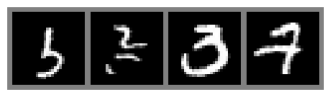

  0%|          | 0/79 [00:00<?, ?it/s]

Test Loss: 0.7124


In [12]:
# Training loop
train_bpd = []
val_bpd = []

for epoch in range(epochs):
    model.train()
    losses = []

    for imgs, _ in tqdm(train_loader, leave=False):
        imgs = imgs.to(device)
        optimizer.zero_grad()
        loss = model.calc_nll(imgs)
        loss.backward()
        optimizer.step()
        losses.append(loss.item())

    train_bpd.append(np.mean(losses))
    scheduler.step()

    losses = []
    with torch.no_grad():
      for imgs, _ in tqdm(val_loader, leave=False):
          imgs = imgs.to(device)
          loss = model.calc_nll(imgs)
          losses.append(loss.item())

    val_bpd.append(np.mean(losses))

    print(f"Epoch {epoch+1}/{epochs}, Train Loss: {train_bpd[-1]:.4f}, Val Loss: {val_bpd[-1]:.4f}")

    #if (epoch + 1) % 5 == 0:
    sampled_images = model.sample(img_shape=(4, 1, 28, 28))
    show_imgs(sampled_images)

# Test loop
model.eval()
losses = []
for imgs, _ in tqdm(test_loader, leave=False):
    imgs = imgs.to(device)
    loss = model.calc_nll(imgs)
    losses.append(loss.item())

test_bpd = np.mean(losses)
print(f"Test Loss: {test_bpd:.4f}")

In [18]:
torch.save({
    'model_state_dict': model.state_dict(),
    'optimizer_state_dict': optimizer.state_dict(),
}, os.path.join(CHECKPOINT_PATH, "pixelcnn.pt"))


## Question 1

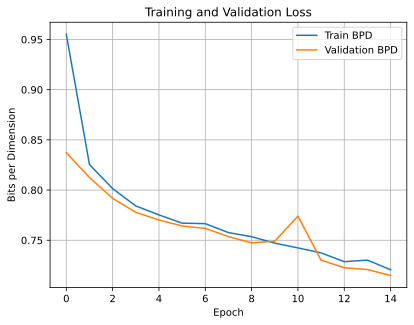

  0%|          | 0/28 [00:00<?, ?it/s]

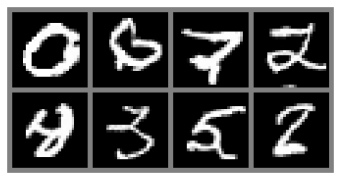

In [15]:
plt.plot(train_bpd, label='Train BPD')
plt.plot(val_bpd, label='Validation BPD')
plt.xlabel('Epoch')
plt.ylabel('Bits per Dimension')
plt.legend()
plt.title('Training and Validation Loss')
plt.grid()
plt.show()
model.eval()
samples = model.sample((8, 1, 28, 28))  # 8 samples
show_imgs(samples)


## Question 2

In [ ]:
class PixelCNN2(nn.Module):
    def __init__(self, c_in=1, c_hidden=64, kernel_size=9, n_layers=7):
        super().__init__()
        # vertical stack keeps center masked, horizontal stack sees center (non-causal)
        self.conv_vstack = VerticalStackConvolution(c_in, c_hidden, kernel_size=kernel_size, mask_center=True)
        self.conv_hstack = HorizontalStackConvolution(c_in, c_hidden, kernel_size=kernel_size, mask_center=False)

        # all stacked layers are non-causal
        self.conv_layers = nn.ModuleList([
            MaskedConvLayer(c_hidden, kernel_size=kernel_size, mask_center=False)
            for _ in range(n_layers)
        ])

        self.conv_out = nn.Conv2d(c_hidden, c_in * 256, kernel_size=1)

    def forward(self, x):
        x = (x.float() / 255.0) * 2 - 1
        v_stack = self.conv_vstack(x)
        h_stack = self.conv_hstack(x)
        for layer in self.conv_layers:
            v_stack, h_stack = layer(v_stack, h_stack)
        out = self.conv_out(F.elu(h_stack + v_stack))
        out = out.reshape(out.shape[0], 256, out.shape[1] // 256, out.shape[2], out.shape[3])
        return out

    def calc_nll(self, x):
        out = self.forward(x)
        out = out.squeeze(2)  # shape [B, 256, H, W]
        target = x.squeeze(1) # shape [B, H, W]
        loss = F.cross_entropy(out, target, reduction='mean')
        return loss / math.log(2)

    @torch.no_grad()
    def sample(self, img_shape, img=None):
        if img is None:
            img = torch.zeros(img_shape, dtype=torch.long).to(device) - 1
        for h in tqdm(range(img_shape[2]), leave=False):
            for w in range(img_shape[3]):
                for c in range(img_shape[1]):
                    if (img[:, c, h, w] != -1).all().item():
                        continue
                    pred = self.forward(img[:, :, :h+1, :])
                    probs = F.softmax(pred[:, :, c, h, w], dim=-1)
                    img[:, c, h, w] = torch.multinomial(probs, num_samples=1).squeeze(dim=-1)
        return img

In [ ]:
model = PixelCNN2(c_in=1, c_hidden=64)       # adjust according to your model
print("Num params: {:,}".format(sum(p.numel() for p in model.parameters())))

model = torch.compile(model.to(device))

optimizer = optim.Adam(model.parameters(), lr=1e-3)
scheduler = optim.lr_scheduler.StepLR(optimizer, 1, gamma=0.99)
epochs = 10

Num params: 2,603,904


  0%|          | 0/390 [00:00<?, ?it/s]

  0%|          | 0/79 [00:00<?, ?it/s]

Epoch 1/10, Train Loss: 1.1324, Val Loss: 0.7542


  0%|          | 0/28 [00:00<?, ?it/s]

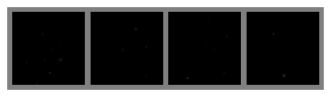

  0%|          | 0/390 [00:00<?, ?it/s]

  0%|          | 0/79 [00:00<?, ?it/s]

Epoch 2/10, Train Loss: 0.7058, Val Loss: 0.7179


  0%|          | 0/28 [00:00<?, ?it/s]

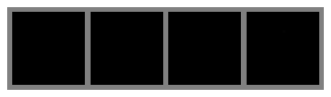

  0%|          | 0/390 [00:00<?, ?it/s]

  0%|          | 0/79 [00:00<?, ?it/s]

Epoch 3/10, Train Loss: 0.6469, Val Loss: 0.6247


  0%|          | 0/28 [00:00<?, ?it/s]

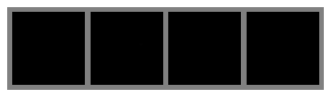

  0%|          | 0/390 [00:00<?, ?it/s]

  0%|          | 0/79 [00:00<?, ?it/s]

Epoch 4/10, Train Loss: 0.6274, Val Loss: 0.5449


  0%|          | 0/28 [00:00<?, ?it/s]

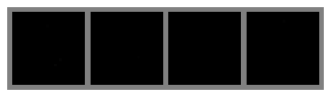

  0%|          | 0/390 [00:00<?, ?it/s]

  0%|          | 0/79 [00:00<?, ?it/s]

Epoch 5/10, Train Loss: 2.4288, Val Loss: 0.8613


  0%|          | 0/28 [00:00<?, ?it/s]

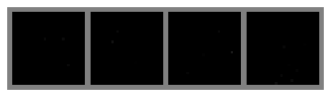

  0%|          | 0/390 [00:00<?, ?it/s]

  0%|          | 0/79 [00:00<?, ?it/s]

Epoch 6/10, Train Loss: 0.6849, Val Loss: 0.6383


  0%|          | 0/28 [00:00<?, ?it/s]

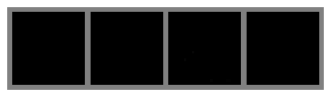

  0%|          | 0/390 [00:00<?, ?it/s]

  0%|          | 0/79 [00:00<?, ?it/s]

Epoch 7/10, Train Loss: 0.5500, Val Loss: 0.5164


  0%|          | 0/28 [00:00<?, ?it/s]

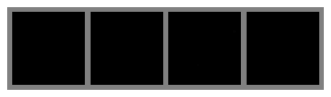

  0%|          | 0/390 [00:00<?, ?it/s]

  0%|          | 0/79 [00:00<?, ?it/s]

Epoch 8/10, Train Loss: 0.5111, Val Loss: 0.4552


  0%|          | 0/28 [00:00<?, ?it/s]

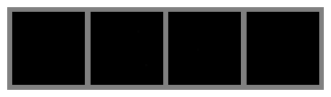

  0%|          | 0/390 [00:00<?, ?it/s]

  0%|          | 0/79 [00:00<?, ?it/s]

Epoch 9/10, Train Loss: 0.5878, Val Loss: 0.4933


  0%|          | 0/28 [00:00<?, ?it/s]

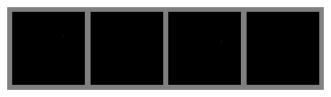

  0%|          | 0/390 [00:00<?, ?it/s]

  0%|          | 0/79 [00:00<?, ?it/s]

Epoch 10/10, Train Loss: 0.4661, Val Loss: 0.4312


  0%|          | 0/28 [00:00<?, ?it/s]

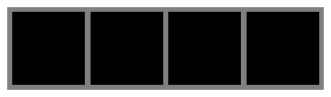

In [ ]:
# Training loop
train_bpd = []
val_bpd = []

for epoch in range(epochs):
    model.train()
    losses = []

    for imgs, _ in tqdm(train_loader, leave=False):
        imgs = imgs.to(device)
        optimizer.zero_grad()
        loss = model.calc_nll(imgs)
        loss.backward()
        optimizer.step()
        losses.append(loss.item())

    train_bpd.append(np.mean(losses))
    scheduler.step()

    losses = []
    with torch.no_grad():
      for imgs, _ in tqdm(val_loader, leave=False):
          imgs = imgs.to(device)
          loss = model.calc_nll(imgs)
          losses.append(loss.item())

    val_bpd.append(np.mean(losses))

    print(f"Epoch {epoch+1}/{epochs}, Train Loss: {train_bpd[-1]:.4f}, Val Loss: {val_bpd[-1]:.4f}")

    #if (epoch + 1) % 5 == 0:
    sampled_images = model.sample(img_shape=(4, 1, 28, 28))
    show_imgs(sampled_images)


In [ ]:
# Test loop
model.eval()
losses = []
for imgs, _ in tqdm(test_loader, leave=False):
    imgs = imgs.to(device)
    loss = model.calc_nll(imgs)
    losses.append(loss.item())

test_bpd = np.mean(losses)
print(f"Test Loss: {test_bpd:.4f}")

  0%|          | 0/79 [00:00<?, ?it/s]

Test Loss: 0.4332


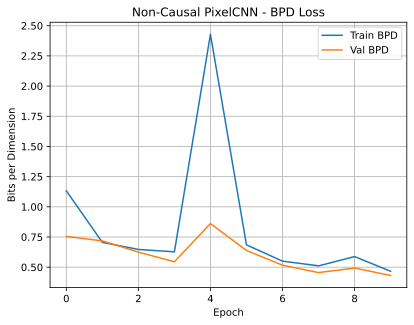

  0%|          | 0/28 [00:00<?, ?it/s]

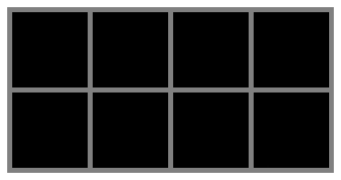

In [ ]:
plt.plot(train_bpd, label="Train BPD")
plt.plot(val_bpd, label="Val BPD")
plt.xlabel("Epoch")
plt.ylabel("Bits per Dimension")
plt.title("Non-Causal PixelCNN - BPD Loss")
plt.legend()
plt.grid()
plt.show()

samples = model.sample((8, 1, 28, 28))
show_imgs(samples)

## Question 2 – Non-Causal PixelCNN - Explanation :
In this part, we removed the causal masking from the horizontal and residual convolutional layers. That means the model had access to the current pixel while trying to predict it. This breaks the autoregressive structure, since PixelCNN is supposed to use only previous pixels.

During training, the loss was lower than the causal version because the model could cheat by using the ground truth pixel it is supposed to predict. But during generation, this pixel is not available anymore, so the samples became meaningless (mostly black).

The model learned to rely on information it won't have at test time, so it failed to generalize. This explains why the loss is low but the samples look wrong.

In summary, the model didn't learn anything (simply because in the training, it was given the "answers") so in the test it failed.

## Question 3

Note: if you want to run the code, run this cell before running the cell you want to check.

In [81]:
# Load the trained model
model = PixelCNN(c_in=1, c_hidden=64, kernel_size=7)

checkpoint = torch.load("pixelcnn.pt")
# Compile the model before loading the state_dict
model = torch.compile(model.to(device))
model.load_state_dict(checkpoint['model_state_dict'])

model.eval()

OptimizedModule(
  (_orig_mod): PixelCNN(
    (conv_vstack): VerticalStackConvolution(
      (conv): Conv2d(1, 64, kernel_size=(7, 7), stride=(1, 1), padding=same)
    )
    (conv_hstack): HorizontalStackConvolution(
      (conv): Conv2d(1, 64, kernel_size=(1, 7), stride=(1, 1), padding=same)
    )
    (conv_layers): ModuleList(
      (0-6): 7 x MaskedConvLayer(
        (vert): Sequential(
          (0): VerticalStackConvolution(
            (conv): Conv2d(64, 64, kernel_size=(7, 7), stride=(1, 1), padding=same)
          )
          (1): ELU(alpha=1.0)
        )
        (horiz_conv): HorizontalStackConvolution(
          (conv): Conv2d(64, 64, kernel_size=(1, 7), stride=(1, 1), padding=same)
        )
        (vert_to_horiz): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1))
        (horiz_activation): ELU(alpha=1.0)
      )
    )
    (conv_out): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1))
  )
)

# 3.a

this is easy,
pixelCNN starts from the top-left, so the first pixel is predicted without conditioning on anything.
we just pass an empty image to the model and get the logits at (0,0), then apply softmax to get the probability.
this gives the marginal distribution of the first pixel.

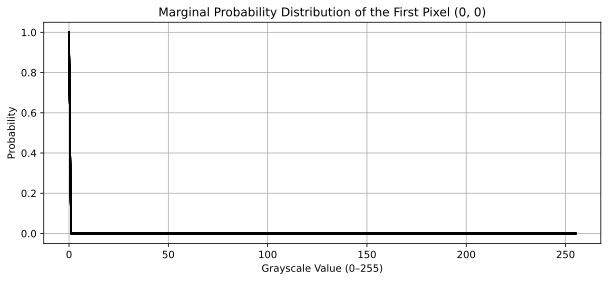

In [40]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from torch.utils import data

det_loader = data.DataLoader(train_set, batch_size=128, shuffle=False, drop_last=False)

imgs, _ = next(iter(det_loader))
imgs = imgs.to(device)

with torch.no_grad():
    model.eval()
    model = model.to(device)

    # Forward pass
    out = model(imgs)  # shape: (batch_size, 256, H, W)

    # Apply softmax over the class/channel dimension
    out_probs = F.softmax(out, dim=1)  # (batch_size, 256, H, W)

    # --------- NEW: Marginal distribution of the first pixel (0,0) ---------
    first_pixel_probs = out_probs[:, :, 0, 0]  # shape: (batch_size, 256)
    marginal_first_pixel = first_pixel_probs.mean(dim=0).cpu().numpy()  # mean over batch

    # Plot
    plt.figure(figsize=(10, 4))
    plt.plot(range(256), marginal_first_pixel, color='black')
    plt.title("Marginal Probability Distribution of the First Pixel (0, 0)")
    plt.xlabel("Grayscale Value (0–255)")
    plt.ylabel("Probability")
    plt.grid(True)
    plt.show()
    # -----------------------------------------------------------------------

    # Your existing computations
    all_pixels_mean = out_probs.mean(dim=[0, 2]).cpu().numpy()
    mean_out = out_probs.mean(dim=[0, 2, 3]).cpu().numpy()
    out_probs = out_probs.cpu().numpy()


# 3.b

this is hard, because we sum over all possible configurations of pixels before (14,14), and the number of combinations is $256^{14 \cdot 28 + 14}$ which is intractable. Therefore, we need to estimate it by sampling full images from the model and collecting the values at pixel (14,14).  
after 100 samples, we count how often each value appears to get an approximate marginal.

In [45]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

# Settings
pixel_y, pixel_x = 14, 14  # middle pixel
num_samples = 100         # number of images to sample from the dataset

# Prepare loader to sample N images
det_loader = data.DataLoader(train_set, batch_size=64, shuffle=True, drop_last=False)
collected_probs = []

model.eval()
model = model.to(device)

with torch.no_grad():
    total_collected = 0

    for imgs, _ in det_loader:
        imgs = imgs.to(device)

        # Forward pass
        out = model(imgs)  # shape: (B, 256, H, W)
        out_probs = F.softmax(out, dim=1)

        # Extract probabilities at pixel (14,14) for each image.
        # The channel dimension (index 2) has size 1.
        # We access the height dimension at index 3 and the width dimension at index 4.
        # The resulting shape is (B, 256) -> probabilities for each class at that pixel for each image in the batch
        pixel_probs = out_probs[:, :, 0, pixel_y, pixel_x] # Access the single channel at index 0

        collected_probs.append(pixel_probs.cpu())  # move to CPU
        total_collected += imgs.size(0)

        if total_collected >= num_samples:
            break  # enough samples

    # Stack and average
    collected_probs = torch.cat(collected_probs, dim=0)[:num_samples]  # (N, 256)
    marginal_prob = collected_probs.mean(dim=0).numpy()  # (256,)


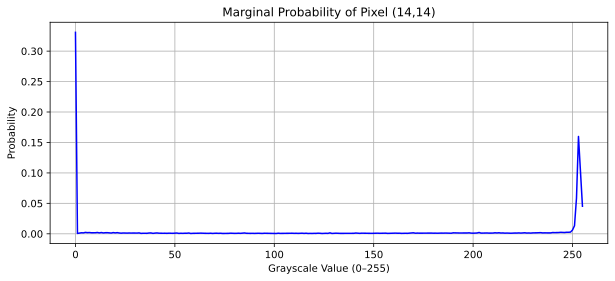

In [46]:
plt.figure(figsize=(10, 4))
plt.plot(range(256), marginal_prob, color='blue')
plt.title("Marginal Probability of Pixel (14,14)")
plt.xlabel("Grayscale Value (0–255)")
plt.ylabel("Probability")
plt.grid(True)
plt.show()


# 3.c

this is easy.
pixelCNN is autoregressive and predicts each pixel based on previous ones (above and to the left).
so we can compute the conditional probability of the middle pixel given those pixels directly.

In [60]:
import torch
import torch.nn.functional as F

pixel_y, pixel_x = 14, 14  # middle pixel

# Get one image from the dataset
loader = data.DataLoader(train_set, batch_size=1, shuffle=False)
img, _ = next(iter(loader))
img = img.to(device)

model.eval()
with torch.no_grad():
    output = model(img)  # shape: (1, 256, H, W)
    probs = F.softmax(output, dim=1)  # convert to probabilities

    # Extract the conditional distribution at (14, 14)
    conditional_prob = probs[0, :, 0, pixel_y, pixel_x]  # shape: (256,)
    conditional_prob = conditional_prob.cpu().numpy()


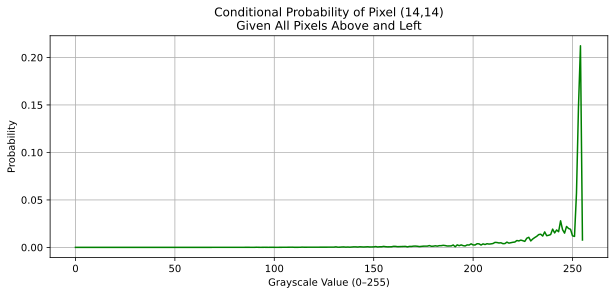

In [61]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 4))
plt.plot(range(256), conditional_prob, color='green')
plt.title("Conditional Probability of Pixel (14,14)\nGiven All Pixels Above and Left")
plt.xlabel("Grayscale Value (0–255)")
plt.ylabel("Probability")
plt.grid(True)
plt.show()


# 3.d

This is hard. PixelCNN cannot condition on future pixels like those below/right. We approximated the conditional distribution of pixel (14,14) by setting future pixel values and letting the model predict as usual. However, since the model was never trained to use those pixels, the results are noisy and unreliable.

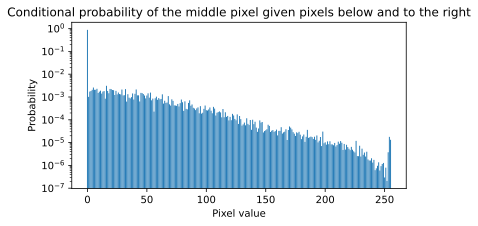

In [69]:
# Set all pixels below and to the right of the middle pixel to zero
simple_im = torch.zeros((1, 1, 28, 28), dtype=torch.int64).to(device)
simple_im[:, :, 15:, :] = 0
simple_im[:, :, :, 15:] = 0

# Get model output
model.eval()
with torch.no_grad():
    out = model(simple_im)
pixel_logits = out[0, :, 0, 14, 14]
pixel_probs = F.softmax(pixel_logits, dim=0).cpu().numpy() # Apply softmax and move to CPU

# Visualize the conditional probability distribution for the middle pixel
plt.figure(figsize=(6,3))
plt.bar(np.arange(len(pixel_probs), dtype=np.int32), pixel_probs)
plt.yscale("log")
plt.title("Conditional probability of the middle pixel given pixels below and to the right")
plt.xlabel("Pixel value")
plt.ylabel("Probability")
plt.show()
plt.close()

# 3.e

This is hard. PixelCNN only conditions on past pixels (top and left), but here we need the conditional probability of the middle pixel given all others (including future ones). We approximate this using Gibbs sampling, where we fix all pixels except (14,14), then sample it multiple times to estimate its distribution.

torch.Size([1, 1, 28, 28])
(784, 784, 28, 1)


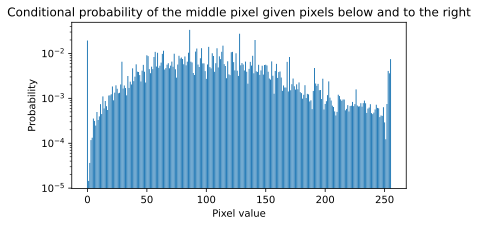

In [93]:
# take a random image
image = train_dataset[0][0].reshape(1, 1, 28, 28).to(device)
true_image = image.clone() # Keep a copy of the original image

print(image.shape)
print(image.stride())


n_iter = 20
with torch.no_grad():
    # Ensure model is in evaluation mode
    model.eval()

    # Move model to the correct device if not already there
    model = model.to(device)
    for _ in range(n_iter):
      for i in range(14):
        for j in range(28):
            if i == 14 and j == 14:
                continue
            # Forward pass through the model
            pixel_propability = model(image)[0, :, 0, i, j]
            pixel_propability_softmax = F.softmax(pixel_propability, dim=0)
            # print(pixel_propability_softmax.shape)
            image[:, :, i, j] = torch.multinomial(pixel_propability_softmax, 1).float()
    mid_px_prob = F.softmax(model(image)[0, :, 0, 14, 14], dim=0).cpu().numpy()
    plt.figure(figsize=(6,3))
    plt.bar(np.arange(len(mid_px_prob), dtype=np.int32), mid_px_prob)
    plt.yscale("log")
    plt.title("Conditional probability of the middle pixel given pixels below and to the right")
    plt.xlabel("Pixel value")
    plt.ylabel("Probability")
    plt.show()
    plt.close()



# 3.f

this is easy
PixelCNN is trained to generate pixels from top-left to bottom-right.
So if we know the top half of the image, we can generate the bottom half by sampling pixels one by one.
We fix the known top part and let the model generate the unknown bottom part in the usual autoregressive way.

In [19]:
loader = data.DataLoader(train_set, batch_size=128, shuffle=False, drop_last=False)
imgs,_ = next(iter(loader))
imgs = imgs.to(device)
with torch.no_grad():
    # Ensure model is in evaluation mode
    model.eval()

    # Move model to the correct device if not already there
    model = model.to(device)

    # Forward pass through the model
    out = model(imgs)

    # Apply softmax to get probabilities
    out = F.softmax(out, dim=1)

    all_pixels_mean = out.mean(dim=[0, 2]).cpu().numpy()

    # Calculate mean output (you might want to modify this based on your specific requirements)
    mean_out = out.mean(dim=[0, 2, 3]).cpu().numpy()

    # Optionally, move output back to CPU for further processing
    out = out.cpu().numpy()

W0523 08:01:00.937000 404 torch/_inductor/utils.py:1137] [0/0] Not enough SMs to use max_autotune_gemm mode


torch.Size([1, 1, 28, 28])


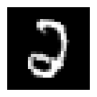

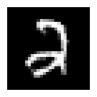

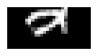

In [21]:
image = imgs[4:5].clone().to(device)
true_image = imgs[4:5].clone().to(device)
with torch.no_grad():
    # Ensure model is in evaluation mode
    model.eval()
    # Move model to the correct device if not already there
    model = model.to(device)
    print(image.shape)
    for i in range(14, 28):
        for j in range(28):
            # Forward pass through the model
            pixel_propability = model(image)[0, :, 0, i, j]
            pixel_propability_softmax = F.softmax(pixel_propability, dim=0)
            # print(pixel_propability_softmax.shape)
            image[:, :, i, j] = torch.multinomial(pixel_propability_softmax, 1).float()

show_imgs(true_image.cpu())
show_imgs(image)
show_imgs(image[:, :, 14:, :])

# 3.g

this is hard
PixelCNN generates pixels from top-left to bottom-right only, so it can’t use future pixels like the bottom half to predict the top half.
Direct sampling isn’t possible, but we can approximate by fixing the bottom and repeatedly resampling the top using Gibbs sampling, which gradually refines the unknown pixels.

torch.Size([1, 1, 28, 28])


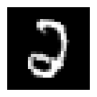

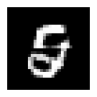

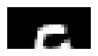

In [26]:
image = imgs[4:5].clone().to(device)
true_image = imgs[4:5].clone().to(device)

with torch.no_grad():
    # Ensure model is in evaluation mode
    model.eval()
    # Move model to the correct device if not already there
    model = model.to(device)
    print(image.shape)
    iterations = 25
    for _ in range(iterations):
        for i in range(14):
            for j in range(28):
                # Forward pass through the model
                pixel_propability = model(image)[0, :, 0, i, j]
                pixel_propability_softmax = F.softmax(pixel_propability, dim=0)
                # print(pixel_propability_softmax.shape)
                image[:, :, i, j] = torch.multinomial(pixel_propability_softmax, 1).float()


show_imgs(true_image.cpu())
show_imgs(image)
show_imgs(image[:, :, :14, :])